In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import pandas as pd
from recover.constants import DATA_DIR

import torch
from torch import nn
import torch.nn.functional as F
import numpy as np

In [4]:
df = pd.read_excel(DATA_DIR / 'poc_data.xlsx')

In [5]:
predictors = [c for c in df.columns if c.startswith('LUH') and c != 'LUH_sum']
response = [c for c in df.columns if c.startswith('ESA')]

In [6]:
df[predictors].sum(axis=1).describe()

count    26215.000000
mean         0.958778
std          0.158298
min          0.001371
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000001
dtype: float64

In [7]:
df['LUH_nodata'] = (1.0 - df[predictors].sum(axis=1)).clip(0.0, 1.0)
df['LUH_nodata']

0        2.887100e-08
1        0.000000e+00
2        0.000000e+00
3        3.377753e-02
4        2.235174e-08
             ...     
26210    1.490116e-08
26211    0.000000e+00
26212    4.330650e-08
26213    7.543571e-03
26214    0.000000e+00
Name: LUH_nodata, Length: 26215, dtype: float64

In [8]:
predictors.append('LUH_nodata')

In [9]:
df[response].sum(axis=1).describe()

count    2.621500e+04
mean     1.000000e+00
std      1.666096e-08
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

In [10]:
predictors

['LUH_pastr',
 'LUH_primf',
 'LUH_primn',
 'LUH_range',
 'LUH_secdf',
 'LUH_secdn',
 'LUH_urban',
 'LUH_crops',
 'LUH_nodata']

In [11]:
response

['ESA_BareAreas',
 'ESA_Cropland',
 'ESA_Forest_Bl_Dec',
 'ESA_Forest_Bl_Ev',
 'ESA_Forest_Woodland',
 'ESA_ForestMosaic',
 'ESA_Grassland',
 'ESA_GrasslandMosaic',
 'ESA_Mangrove',
 'ESA_Shrubland',
 'ESA_SnowIce',
 'ESA_SparseVegetation',
 'ESA_Urban',
 'ESA_Varzea',
 'ESA_Water']

# Data handling
Functions to retrieve rasters from df, generate test patches and plot

In [12]:
def coord_to_px(x, y, df=df):
    unique_x = df.x.drop_duplicates()
    unique_y = df.y.drop_duplicates()

    x_map = unique_x.rank().astype(int) - 1
    x_map.index = unique_x.values

    y_map = unique_y.rank(ascending=False).astype(int) - 1
    y_map.index = unique_y.values

    return x_map.loc[x], y_map.loc[y]

def px_to_coord(x, y, df=df):
    unique_x = df.x.drop_duplicates()
    unique_y = df.y.drop_duplicates()

    x_map = unique_x.rank().astype(int) - 1
    x_map.index = unique_x.values
    x_map = pd.Series(x_map.index, index=x_map.values)

    y_map = unique_y.rank(ascending=False).astype(int) - 1
    y_map.index = unique_y.values
    y_map = pd.Series(y_map.index, index=y_map.values)

    return x_map.loc[x].values, y_map.loc[y].values

In [13]:
import matplotlib.pyplot as plt
import numpy as np

W, H = df.x.nunique(), df.y.nunique()

def to_img(df, cols=response, masked=True):
    if isinstance(cols, str):
        cols = [cols]
    
    img = np.zeros((H, W, len(cols)))

    xx, yy = coord_to_px(df['x'], df['y'])

    for x, y, (_, row) in zip(xx, yy, df.iterrows()):
        for i, c in enumerate(cols):
            img[y, x, i] = row[c]

    if masked:
        mask = np.broadcast_to(np.all(img == 0, axis=-1, keepdims=True), img.shape)
        img = np.ma.masked_array(img, mask)

    return img

def show_raster(img, cmap='viridis', fig=None, channel_names=None):
    if not fig:
        fig = plt.figure()
    if img.ndim == 2 or (img.ndim == 3 and img.shape[-1] == 1):
        return plt.imshow(img, cmap=cmap)
    
    if img.ndim == 3:
        if img.shape[-1] == 3:
            return plt.imshow(img)
        else:
            cols = 4
            n = img.shape[-1]
            rows = n // cols + (1 if (n % cols) else 0)
            fig = plt.figure(figsize=(cols * 5, rows * 5))
            
            for i in range(n):
                plt.subplot(rows, cols, i+1)
                plt.imshow(img[:, :, i], cmap=cmap)
                if channel_names:
                    plt.title(channel_names[i])
            return fig.tight_layout()


<Figure size 640x480 with 0 Axes>

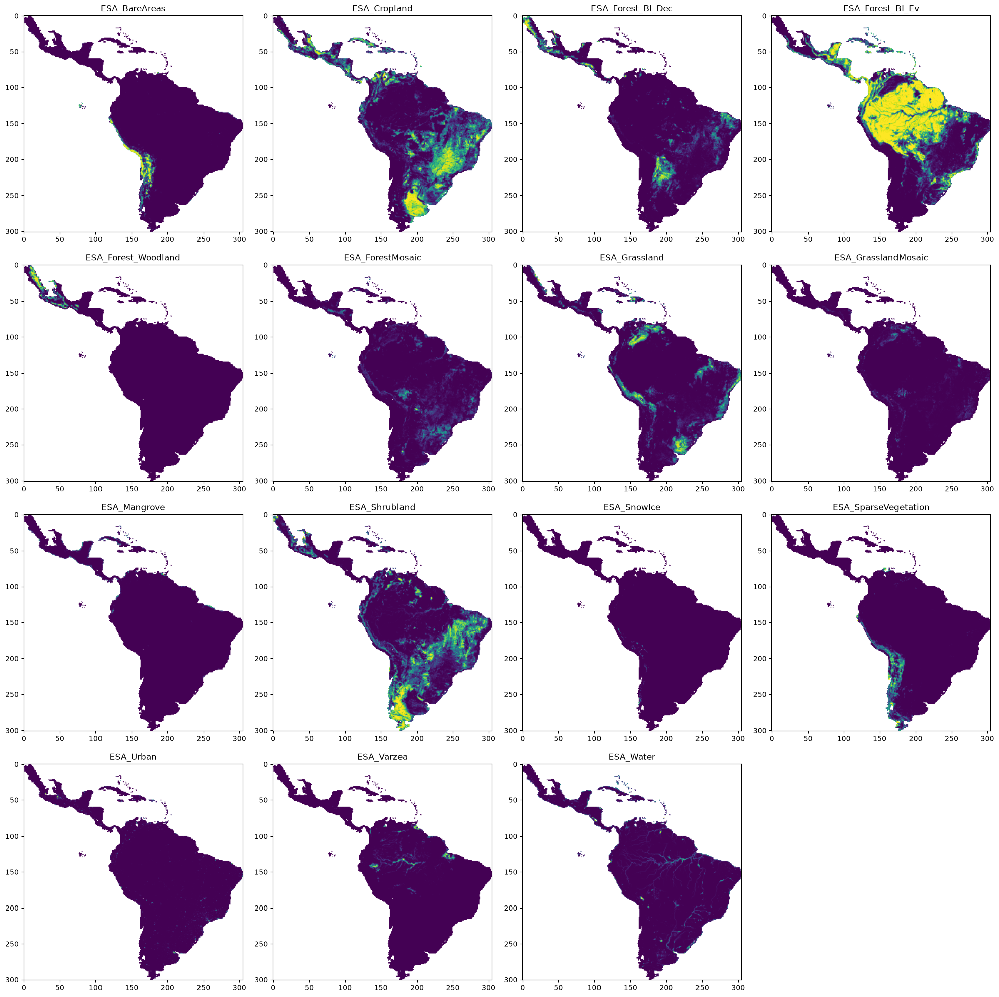

In [14]:
esa = to_img(df, response)
show_raster(esa, channel_names=response)

<Figure size 640x480 with 0 Axes>

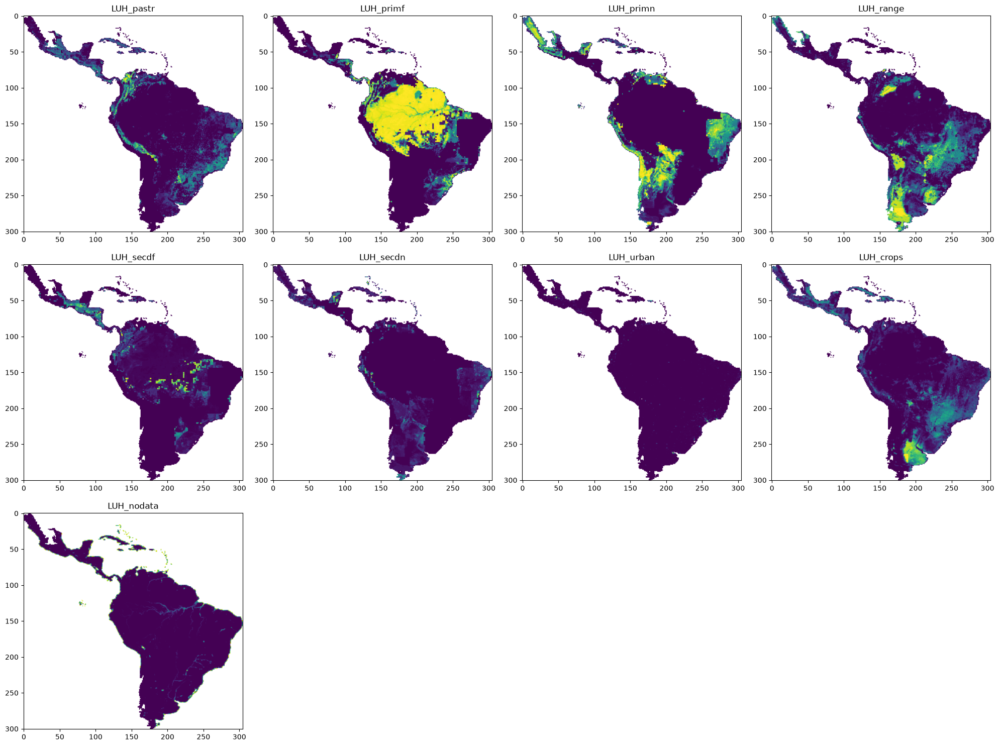

In [15]:
luh = to_img(df, predictors)
show_raster(luh, channel_names=predictors)

In [16]:
import numpy as np
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression

class SimplexRegression:
    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, pd.DataFrame):
            y = y.values

        n, p = X.shape
        d = y.shape[1]

        def objective(b):
            B = b.reshape(d, p)
            y_pred = X @ B.T
            return np.sum((y - y_pred) ** 2)

        # column sums = 1
        constraints = [
            {
                "type": "eq",
                "fun": lambda b, j=j: b.reshape(d, p)[:, j].sum() - 1
            }
            for j in range(p)
        ]

        # B >= 0
        bounds = [(0, None)] * (d * p)

        B0 = np.full((d, p), 1 / d)

        self._result = minimize(
            objective,
            B0.ravel(),
            method="SLSQP",
            bounds=bounds,
            constraints=constraints,
            options={"maxiter": 5000}
        )

        self.B = self._result.x.reshape(d, p)
        return self

    def predict(self, X):
        return X @ self.B.T
    

class MultiOutputOLS():
    def __init__(self):
        self.models = []
    
    def fit(self, X, y):
        assert y.ndim == 2, f'y must be a 2d matrix or dataframe, received {type(y)} with shape {y.shape}'
        if isinstance(y, pd.DataFrame):
            y = y.copy().to_numpy()

        for col_idx in range(y.shape[1]):
            model = LinearRegression(positive=True)
            model.fit(X, y[:, col_idx])
            self.models.append(model)

        return self

    def _process_preds(self, preds: np.ndarray, eps=1e-12):
        preds = preds.clip(eps, 1.0)
        preds = preds / preds.sum(axis=1).reshape(-1, 1)
        return preds

    def predict(self, X):
        raw_preds = []
        for m in self.models:
            raw_preds.append(m.predict(X).reshape(-1, 1))
        
        raw_preds = np.hstack([
            np.array(preds) for preds in raw_preds
        ])

        return self._process_preds(raw_preds)

In [17]:
from scipy.special import rel_entr
import numpy as np

def kl_divergence(y_true, y_pred, eps=1e-12):
    if isinstance(y_true, pd.DataFrame):
        y_true = y_true.copy().to_numpy()
    if isinstance(y_pred, pd.DataFrame):
        y_pred = y_pred.copy().to_numpy()

    y_pred = np.clip(y_pred, eps, 1.0)
    y_pred = y_pred / y_pred.sum(axis=1, keepdims=True)
    return np.mean(np.sum(rel_entr(y_true, y_pred), axis=1))


def js_divergence(y_true, y_pred, eps=1e-12):
    if isinstance(y_true, pd.DataFrame):
        y_true = y_true.copy().to_numpy()
    if isinstance(y_pred, pd.DataFrame):
        y_pred = y_pred.copy().to_numpy()

    y_true = np.clip(y_true, eps, 1.0)
    y_pred = np.clip(y_pred, eps, 1.0)

    y_true /= y_true.sum(axis=1, keepdims=True)
    y_pred /= y_pred.sum(axis=1, keepdims=True)

    m = 0.5 * (y_true + y_pred)

    js = 0.5 * (
        np.sum(rel_entr(y_true, m), axis=1)
        + np.sum(rel_entr(y_pred, m), axis=1)
    )

    return np.mean(js)

def evaluate(y_true, y_pred, metrics=[kl_divergence, js_divergence], name='result'):
    return pd.Series({m.__name__: m(y_true, y_pred) for m in metrics}, name=name)


In [19]:
X = df[predictors].copy()
y = df[response].copy()

# Baseline model comparison
In-sample checks on the single raster provided

## Mean predictor

In [20]:
y_mean = df[response].mean(axis=0)
y_mean = np.repeat(y_mean.to_numpy().reshape(1, -1), len(df), axis=0)

In [72]:
df[response].mean(axis=0)

ESA_BareAreas           0.023915
ESA_Cropland            0.205088
ESA_Forest_Bl_Dec       0.054163
ESA_Forest_Bl_Ev        0.380563
ESA_Forest_Woodland     0.012833
ESA_ForestMosaic        0.026234
ESA_Grassland           0.064215
ESA_GrasslandMosaic     0.005787
ESA_Mangrove            0.003852
ESA_Shrubland           0.162147
ESA_SnowIce             0.000431
ESA_SparseVegetation    0.025668
ESA_Urban               0.004707
ESA_Varzea              0.010107
ESA_Water               0.020288
dtype: float64

In [21]:
evaluate(df[response], y_mean)

kl_divergence    1.105105
js_divergence    0.267140
Name: result, dtype: float64

## OLS baseline

In [22]:
ols = MultiOutputOLS().fit(X, y)
y_pred_ols = ols.predict(X)

In [23]:
evaluate(df[response], y_pred_ols)

kl_divergence    0.693102
js_divergence    0.144080
Name: result, dtype: float64

## Simplex regression

In [24]:
simplex = SimplexRegression().fit(X, y)
y_pred_simplex = simplex.predict(X)

In [25]:
simplex._result

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 4890.499457362289
           x: [ 8.799e-13  1.834e-13 ...  3.217e-11  2.818e-01]
         nit: 114
         jac: [ 5.555e+01  1.148e+01 ... -3.149e+01 -9.393e-01]
        nfev: 15528
        njev: 113
 multipliers: [-1.710e+01 -7.243e+00 -6.407e+00 -6.859e+01 -2.813e+00
               -1.866e+00 -1.237e+00 -3.858e+02 -9.426e-01]

In [26]:
evaluate(df[response], y_pred_simplex)

kl_divergence    0.638970
js_divergence    0.147518
Name: result, dtype: float64

### Visualise OLS

<Figure size 640x480 with 0 Axes>

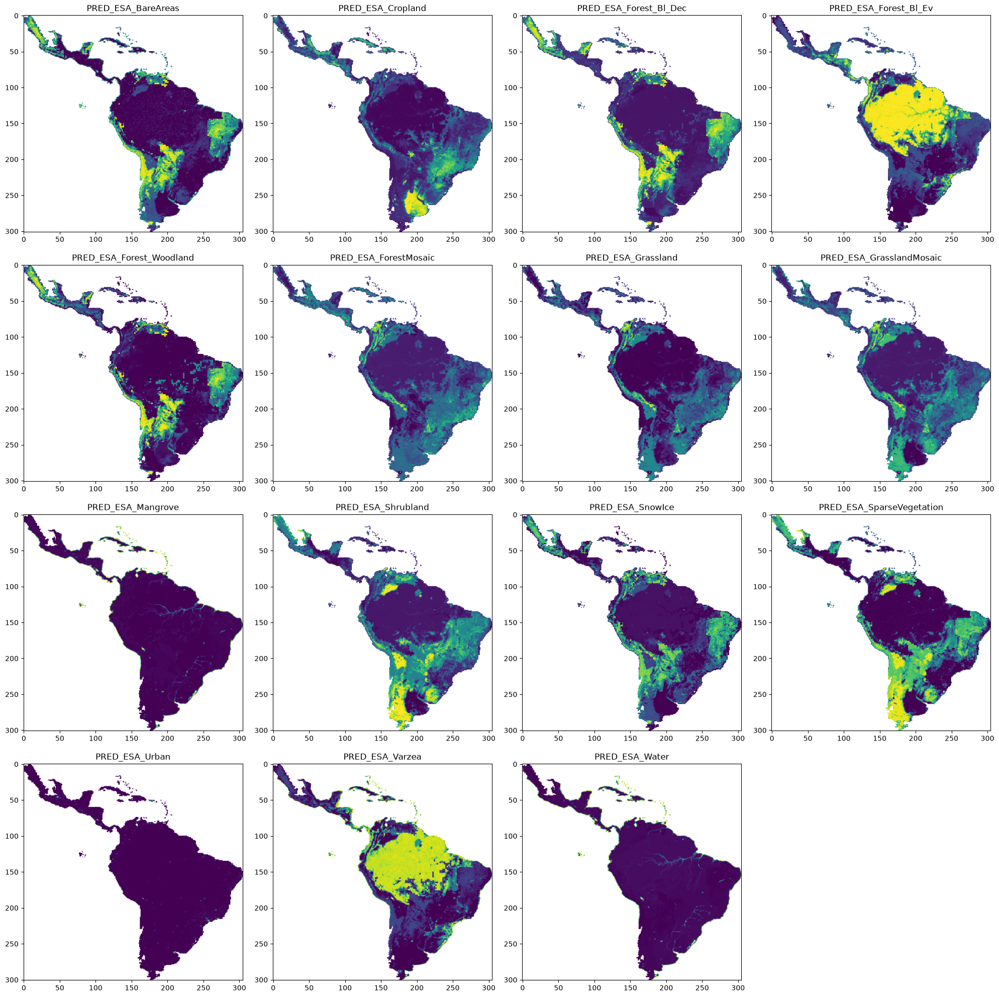

In [27]:
y_pred_ols = pd.DataFrame(y_pred_ols)
y_pred_ols.columns = y.columns
show_raster(to_img(y_pred_ols.join(df[['x', 'y']]), response), channel_names=['PRED_' + r for r in response])

<Figure size 640x480 with 0 Axes>

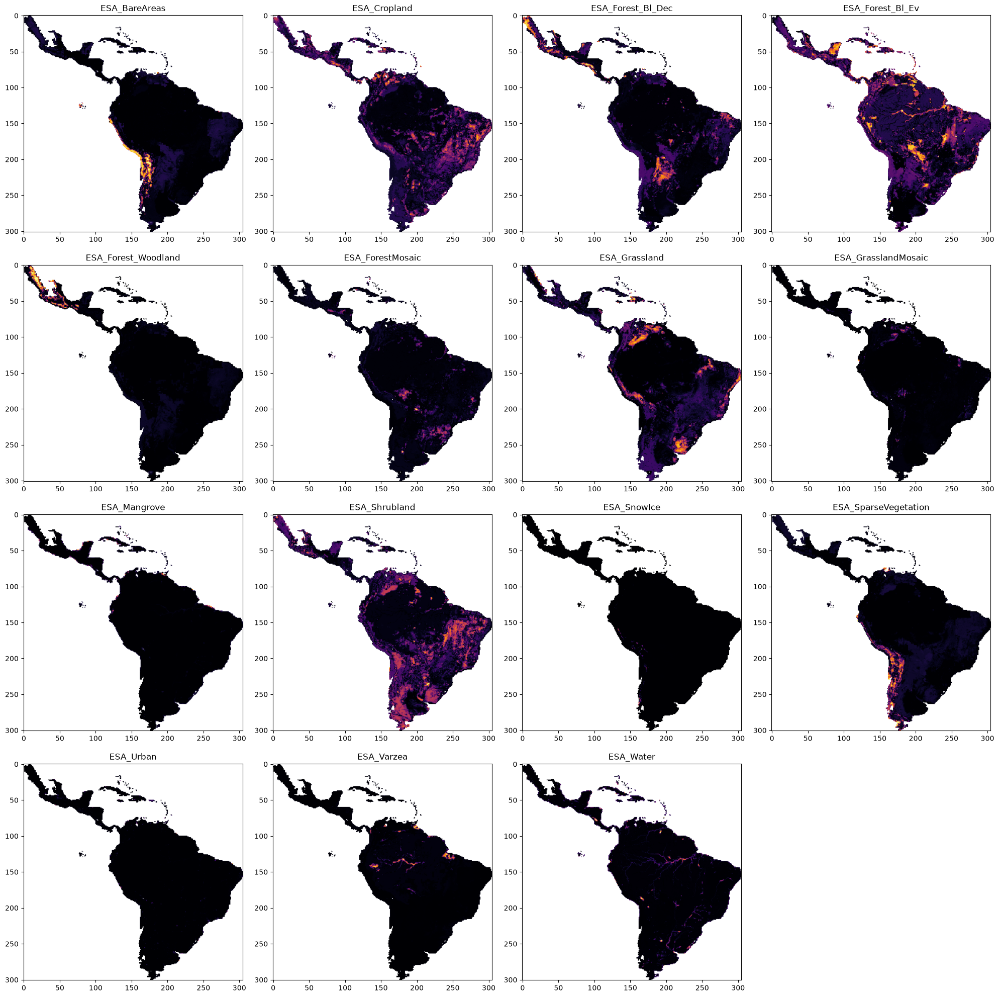

In [27]:
errors = (y_pred_ols - y).abs()
show_raster(to_img(errors.join(df[['x', 'y']]), response), channel_names=response, cmap='inferno')

### Visualise Simplex

<Figure size 640x480 with 0 Axes>

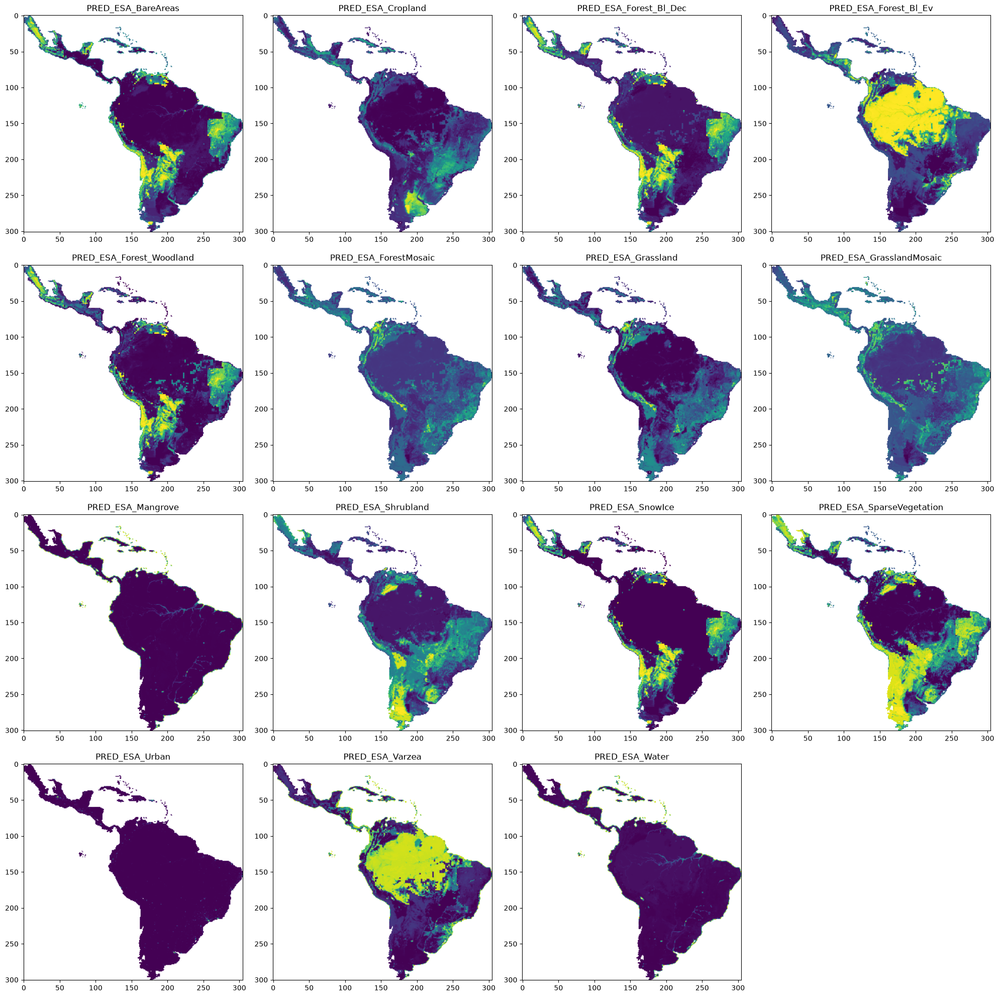

In [28]:
y_pred_simplex.columns = y.columns
show_raster(to_img(y_pred_simplex.join(df[['x', 'y']]), response), channel_names=['PRED_' + r for r in response])

<Figure size 640x480 with 0 Axes>

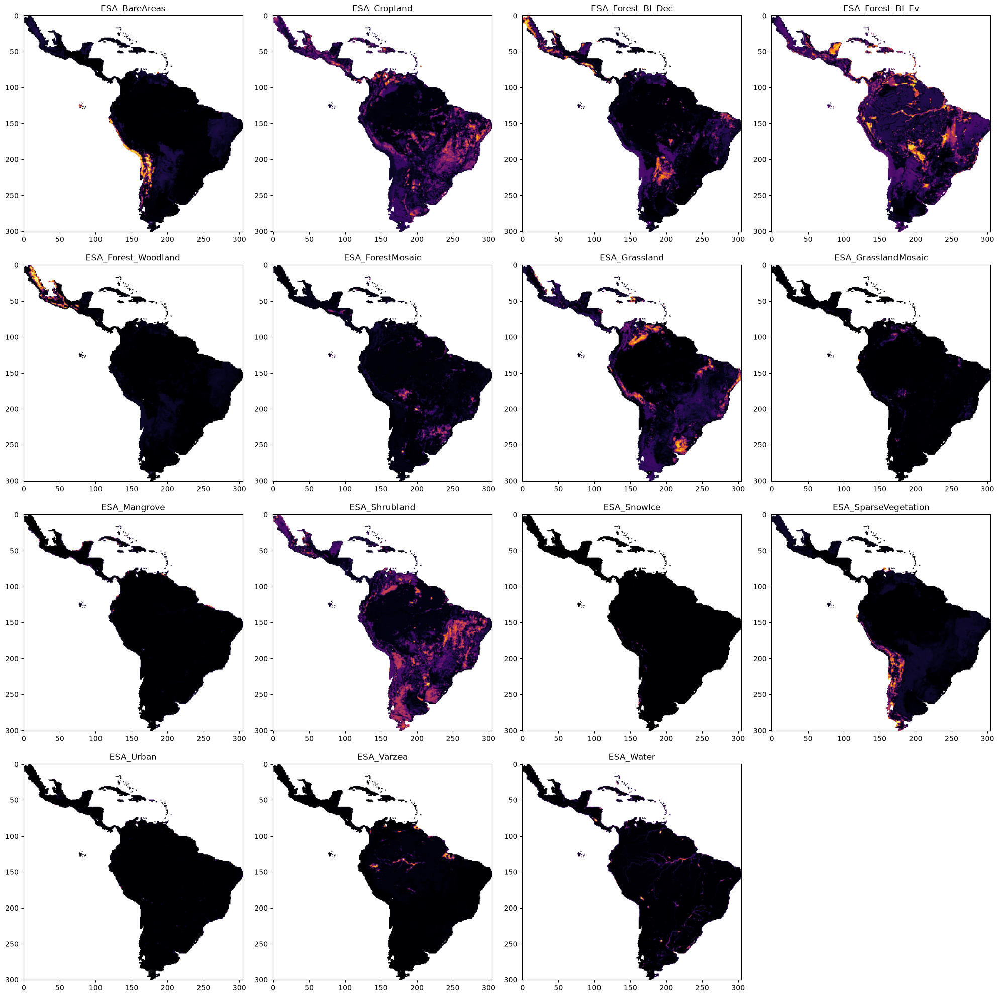

In [29]:
errors = (y_pred_simplex - y).abs()
show_raster(to_img(errors.join(df[['x', 'y']]), response), channel_names=response, cmap='inferno')

# Non-linear methods

## Dense neural network with held out area patches

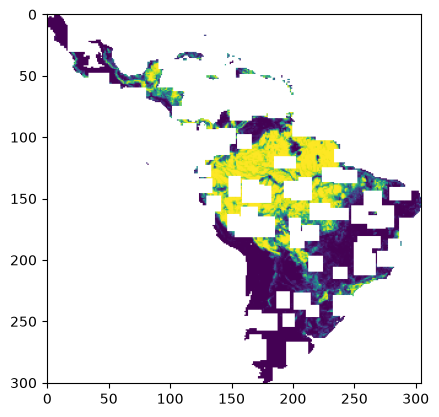

In [73]:
def get_test_patches(df, val_fraction, min_size=10, max_size=20):
    w, h = df.x.nunique(), df.y.nunique()

    total_area = len(df)

    val_mask = np.zeros((h, w)).astype(bool)
    val_indices = []

    # Generate 200 random boxes
    box_positions = np.random.randint(0, w - min_size, (200, 2))
    box_shapes = np.random.randint(min_size, max_size, (200, 2))

    for pos, shape in zip(box_positions, box_shapes):
        # Create a random box
        bx, by = pos
        bw, bh = shape

        x0, x1 = bx, min(bx + bw, w - 1)
        y0, y1 = by, min(by + bh, h - 1)
        
        val_mask[y0:y1, x0:x1] = True

        xcoords, ycoords = px_to_coord([x0, x1], [y0, y1])

        val_indices.extend(df[df.x.between(*xcoords, inclusive='both') & df.y.between(*sorted(ycoords), inclusive='both')].index)
        val_indices = list(set(val_indices))  # Remove duplicate indices

        if (len(val_indices) / total_area) >= val_fraction:
            break

    return val_mask, val_indices


mask, indices = get_test_patches(df, 0.75)

show_raster(np.ma.masked_array(esa, np.broadcast_to(mask.reshape(*mask.shape, 1), esa.shape))[:, :, 3])


# Training loop

In [41]:
from IPython.display import clear_output
from collections import defaultdict

from torch.utils.data import Dataset, DataLoader

class CompositionModel(nn.Module):
    def __init__(
        self,
        input_dim: int,
        output_dim: int,
        hidden_dims=(128, 64),
        dropout=0.1,
    ):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.ReLU(),
            ])
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim

        self.backbone = nn.Sequential(*layers)
        self.head = nn.Linear(prev_dim, output_dim)
    
    def forward(self, x):
        return self.head(self.backbone(x))

    def predict_proba(self, x):
        logits = self.forward(x)
        return F.softmax(logits, dim=-1)


class DFCompositionalDataset(Dataset):
    def __init__(self, df, feature_cols, target_cols):
        self.x = df[feature_cols].values
        self.y = df[target_cols].values

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        x = torch.tensor(self.x[idx], dtype=torch.float32)
        y = torch.tensor(self.y[idx], dtype=torch.float32)
        return x, y


def create_dataloaders(
    df,
    feature_cols,
    target_cols,
    batch_size=128,
    val_fraction=0.2,
    shuffle=True,
):
    _, val_idx = get_test_patches(df, val_fraction)

    val_df = df.loc[val_idx]
    train_df = df.loc[~df.index.isin(val_df)]

    train_ds = DFCompositionalDataset(train_df, feature_cols, target_cols)
    val_ds = DFCompositionalDataset(val_df, feature_cols, target_cols)

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=False,
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        drop_last=False,
    )

    return train_loader, val_loader, val_idx


In [42]:

def train_model(
    model,
    train_loader,
    val_loader=None,
    epochs=50,
    lr=1e-3,
    device="cpu",
):
    model = model.to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = defaultdict(list)

    for epoch in range(epochs):
        model.train()

        train_loss = 0.0

        for x, y in train_loader:
            x = x.to(device).float()
            y = y.to(device).float()

            optimizer.zero_grad()
            
            logits = model(x)

            loss = F.kl_div(
                F.log_softmax(logits, dim=-1),
                y,
                reduction="batchmean",
            )

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * x.size(0)

        train_loss /= len(train_loader.dataset)
        history['train_loss'].append(train_loss)

        msg = f"epoch={epoch+1:03d} train_loss={train_loss:.6f}"

        if val_loader is not None:
            model.eval()

            val_loss = 0.0

            with torch.no_grad():
                for x, y in val_loader:
                    x = x.to(device).float()
                    y = y.to(device).float()

                    logits = model(x)

                    loss = F.kl_div(
                        F.log_softmax(logits, dim=-1),
                        y,
                        reduction="batchmean",
                    )

                    val_loss += loss.item() * x.size(0)

            val_loss /= len(val_loader.dataset)
            history['val_loss'].append(val_loss)
            msg += f" val_loss={val_loss:.6f}"
        
        train_eval_loss = 0.0

        with torch.no_grad():
            for x, y in train_loader:
                x = x.to(device).float()
                y = y.to(device).float()

                logits = model(x)

                loss = F.kl_div(
                    F.log_softmax(logits, dim=-1),
                    y,
                    reduction="batchmean",
                )

                train_eval_loss += loss.item() * x.size(0)

        train_eval_loss /= len(train_loader.dataset)

        msg += f" train_eval_loss={train_eval_loss:.6f}"
        history['train_eval_loss'].append(train_eval_loss)

        if epoch % 10 == 0:
            clear_output(wait=True)
        
        print(msg)

    return model, history

In [44]:
train, val, val_idx = create_dataloaders(
    df,
    feature_cols=predictors,
    target_cols=response,
    batch_size=128,
    val_fraction=0.20,
    shuffle=True
)


In [45]:
def entropy(y):
    y = y.clamp_min(1e-8)
    return -(y * y.log()).sum(dim=1).mean()

In [46]:
model = CompositionModel(
    input_dim=len(predictors), output_dim=len(response), hidden_dims=(128, 64), dropout=0.0
)
print(model.backbone)
print(model.head)

Sequential(
  (0): Linear(in_features=9, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
)
Linear(in_features=64, out_features=15, bias=True)


In [48]:
trained_model, history = train_model(
    model,
    train,
    val,
    epochs=100,
    lr=0.001,
    device='cuda'
)

epoch=091 train_loss=0.407418 val_loss=0.337030 train_eval_loss=0.406325
epoch=092 train_loss=0.407295 val_loss=0.334426 train_eval_loss=0.403271
epoch=093 train_loss=0.405780 val_loss=0.336176 train_eval_loss=0.403669
epoch=094 train_loss=0.407332 val_loss=0.337638 train_eval_loss=0.404549
epoch=095 train_loss=0.406741 val_loss=0.333314 train_eval_loss=0.404167
epoch=096 train_loss=0.404884 val_loss=0.338512 train_eval_loss=0.403290
epoch=097 train_loss=0.404660 val_loss=0.336698 train_eval_loss=0.403160
epoch=098 train_loss=0.404381 val_loss=0.332501 train_eval_loss=0.402463
epoch=099 train_loss=0.405247 val_loss=0.336738 train_eval_loss=0.401853
epoch=100 train_loss=0.403779 val_loss=0.337532 train_eval_loss=0.402167


<Axes: >

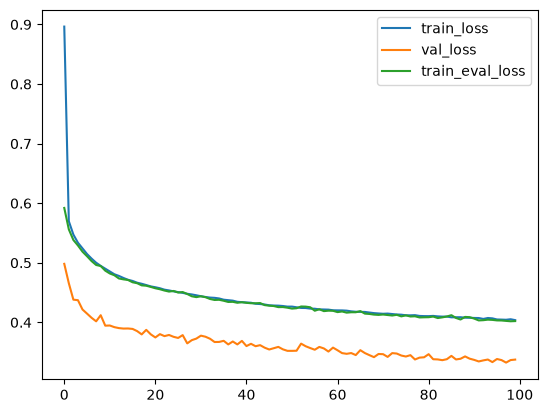

In [49]:
pd.DataFrame(history).plot()

# Visualise predictions

In [50]:
def predict(model, loader):
    device = next(model.parameters()).device
    model.eval()

    predictions = []

    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            predictions.append(model.predict_proba(x).cpu())

    return torch.cat(predictions).detach().numpy()

# preds = []
# for X, y in val:
#     preds.extend(model.predict_proba(X).detach().numpy())

preds = predict(model, val)

In [51]:
preds

array([[4.80870120e-02, 2.91320831e-02, 5.15712872e-02, ...,
        5.91899327e-04, 1.15121750e-03, 4.84749535e-03],
       [1.70734245e-02, 2.83963718e-02, 4.86566350e-02, ...,
        3.51086375e-04, 4.38650837e-04, 4.36264742e-03],
       [1.52000934e-02, 1.20551676e-01, 4.70049456e-02, ...,
        8.84125009e-04, 2.97121471e-04, 6.28558826e-03],
       ...,
       [5.89379258e-02, 1.15614027e-01, 5.57770673e-03, ...,
        1.87268329e-03, 1.13372353e-03, 7.06168562e-02],
       [6.58603087e-02, 1.30950511e-01, 5.78155229e-03, ...,
        1.91865757e-03, 6.06172252e-04, 4.44853678e-02],
       [6.67978777e-03, 4.59737003e-01, 1.02928532e-02, ...,
        3.49647063e-03, 4.67455757e-05, 4.39410144e-03]],
      shape=(5280, 15), dtype=float32)

In [52]:
response_pred = [c + '__pred' for c in response]

pred_df = pd.DataFrame(preds, columns=response, index=val_idx)
pred_only_df = df[['x', 'y']].join(pred_df)

In [53]:
pred_df_with_training = df.copy()
pred_df_with_training.loc[pred_df.index, response] = pred_df[response]

In [54]:
pred_raster = to_img(pred_only_df, response)
val_raster = to_img(df.loc[val_idx])

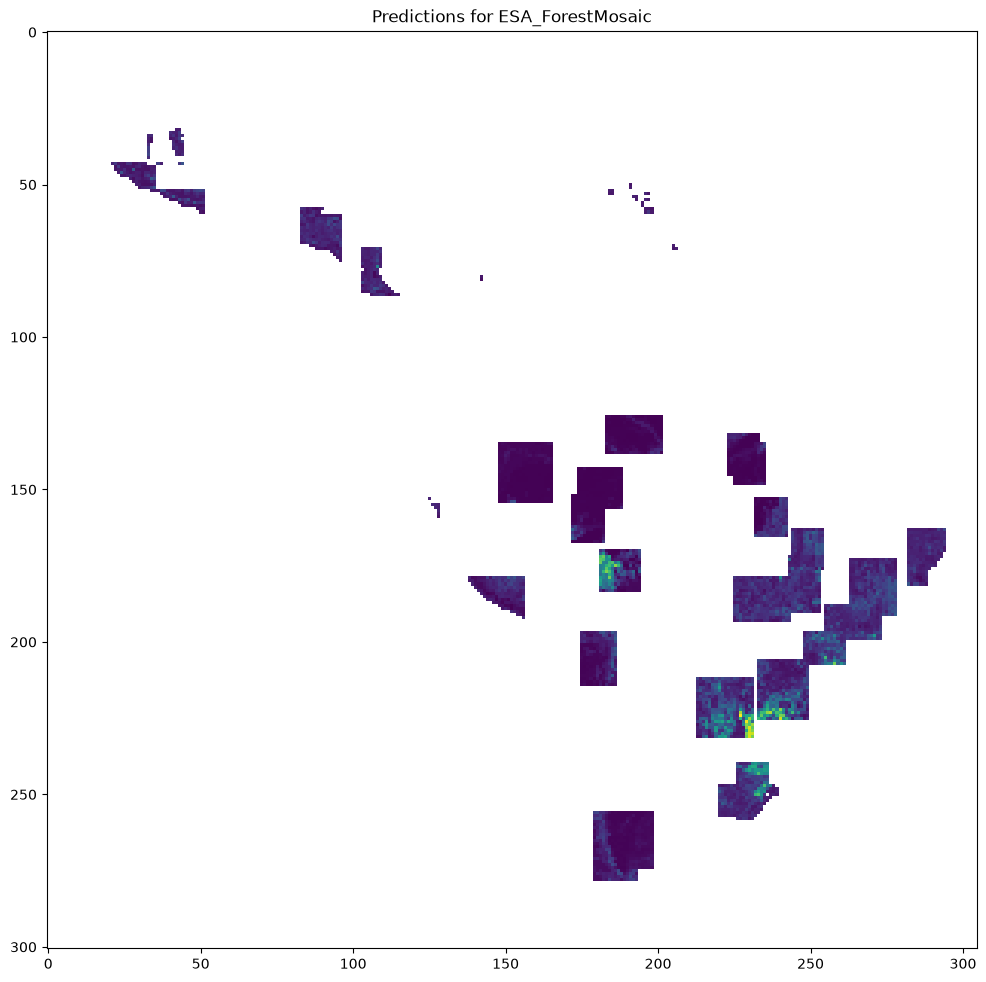

In [76]:
channel_idx = 5
show_raster(to_img(pred_only_df)[:, :, channel_idx], cmap='viridis', fig=plt.figure(figsize=(12, 12)))
plt.title(f'Predictions for {response[channel_idx]}');

In [77]:
print('Sample predictions:')
pred_only_df[['x', 'y'] + response].dropna().sample(15).round(3)

Sample predictions:


,x,y,ESA_BareAreas,ESA_Cropland,ESA_Forest_Bl_Dec,ESA_Forest_Bl_Ev,ESA_Forest_Woodland,ESA_ForestMosaic,ESA_Grassland,ESA_GrasslandMosaic,ESA_Mangrove,ESA_Shrubland,ESA_SnowIce,ESA_SparseVegetation,ESA_Urban,ESA_Varzea,ESA_Water
25751,-64.125,-38.625,0.000,0.045,0.008,0.019,0.000,0.028,0.146,0.009,0.000,0.729,0.0,0.007,0.000,0.001,0.008
24067,-51.625,-31.625,0.004,0.354,0.048,0.218,0.000,0.023,0.060,0.003,0.058,0.041,0.0,0.002,0.010,0.004,0.176
11914,-67.125,-7.375,0.000,0.006,0.004,0.961,0.000,0.002,0.001,0.000,0.000,0.009,0.0,0.000,0.000,0.013,0.003
17214,-43.625,-15.375,0.000,0.415,0.027,0.051,0.001,0.052,0.182,0.014,0.000,0.244,0.0,0.007,0.002,0.001,0.004
17602,-53.625,-16.125,0.000,0.363,0.018,0.045,0.000,0.032,0.149,0.005,0.000,0.384,0.0,0.001,0.000,0.000,0.003
25499,-61.875,-37.375,0.000,0.850,0.013,0.013,0.000,0.011,0.040,0.001,0.000,0.062,0.0,0.000,0.003,0.000,0.006
16507,-73.625,-14.375,0.013,0.282,0.022,0.056,0.002,0.043,0.155,0.008,0.000,0.378,0.0,0.033,0.002,0.000,0.005
19918,-46.625,-20.625,0.000,0.645,0.008,0.056,0.000,0.058,0.037,0.002,0.002,0.058,0.0,0.000,0.045,0.001,0.087
8868,-71.125,-3.125,0.000,0.009,0.002,0.925,0.000,0.005,0.003,0.001,0.000,0.014,0.0,0.000,0.000,0.034,0.007
14619,-40.125,-11.125,0.000,0.366,0.142,0.138,0.060,0.029,0.107,0.005,0.000,0.146,0.0,0.000,0.002,0.001,0.002


In [80]:
predictors

['LUH_pastr',
 'LUH_primf',
 'LUH_primn',
 'LUH_range',
 'LUH_secdf',
 'LUH_secdn',
 'LUH_urban',
 'LUH_crops',
 'LUH_nodata']

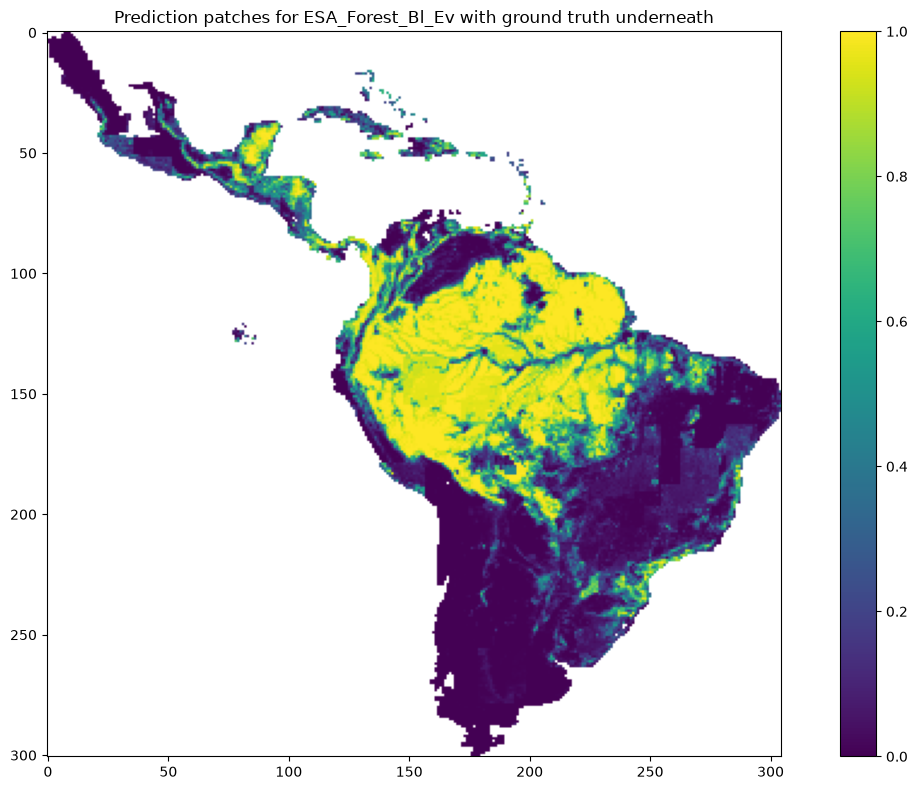

In [81]:
channel_idx = 3
fig = show_raster(to_img(pred_df_with_training)[:, :, channel_idx], cmap='viridis', fig=plt.figure(figsize=(12, 8)))
plt.colorbar()
plt.title(f'Prediction patches for {response[channel_idx]} with ground truth underneath');
plt.gcf().tight_layout()

## All channels side by side

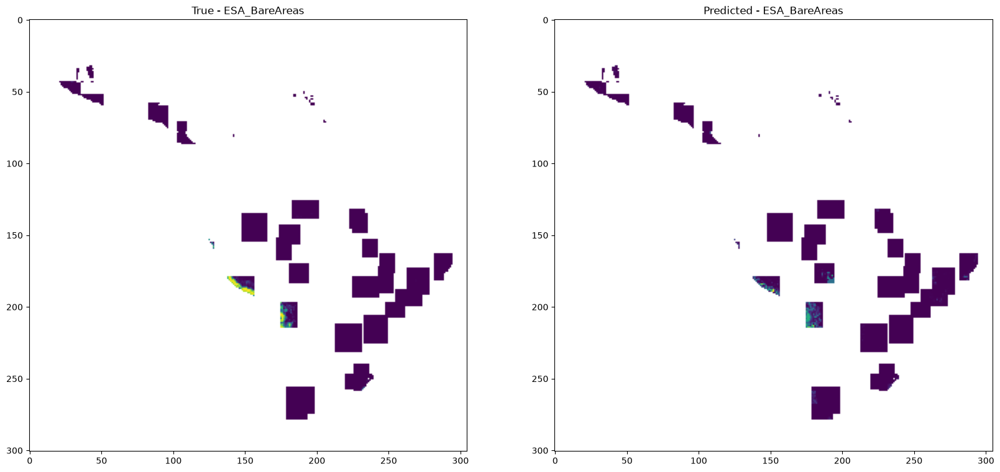

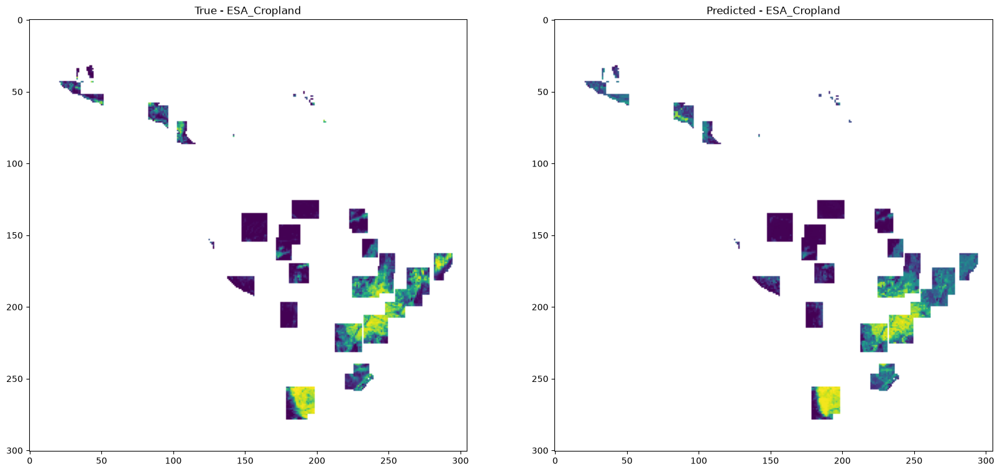

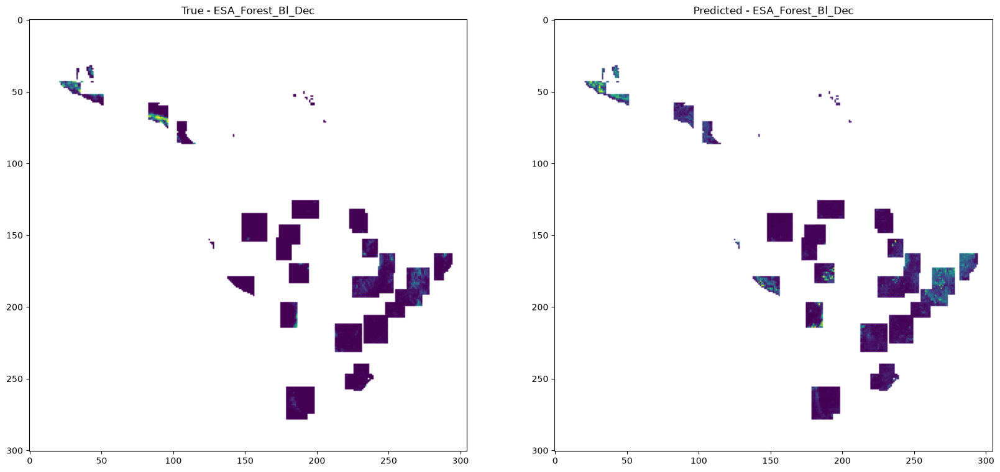

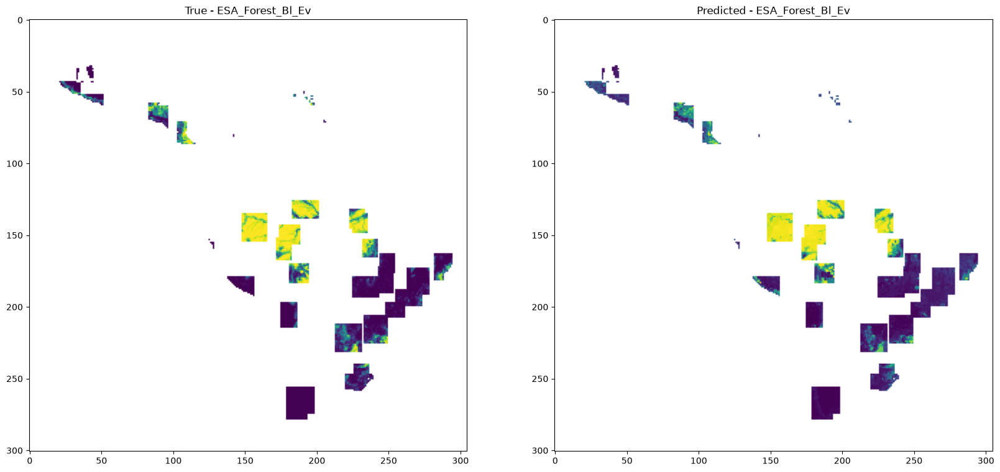

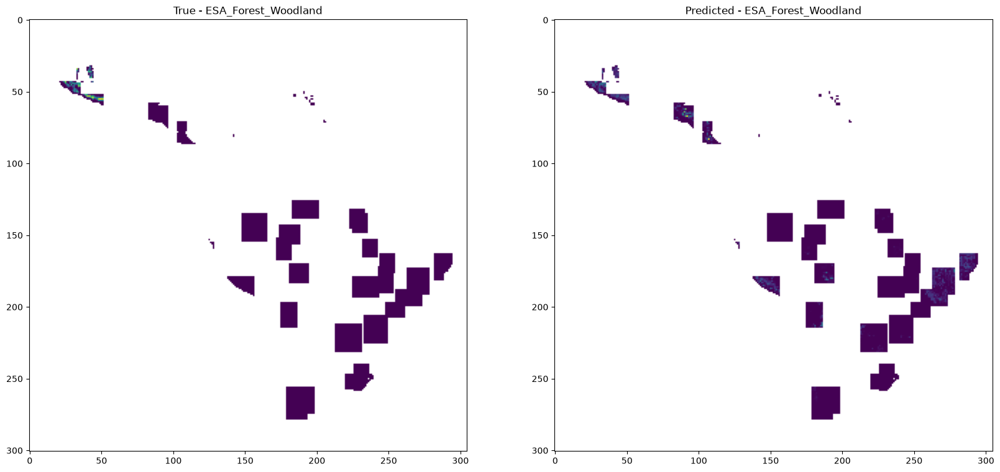

...

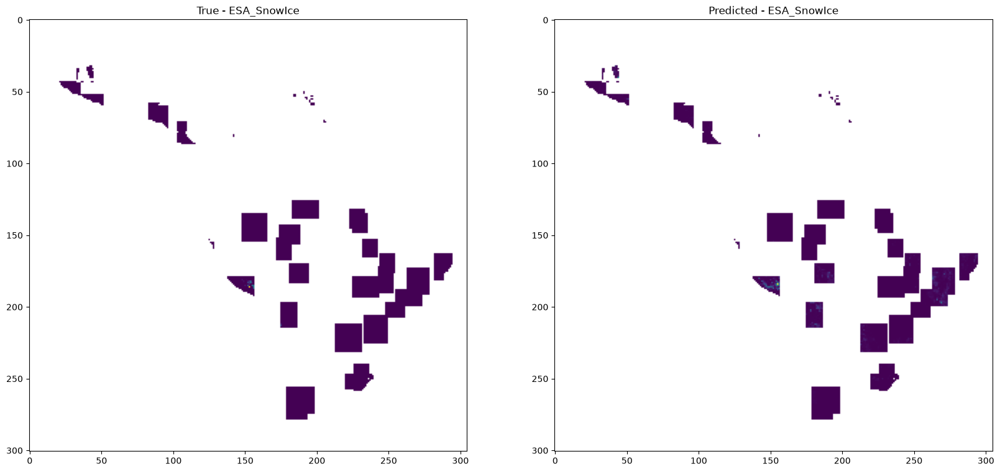

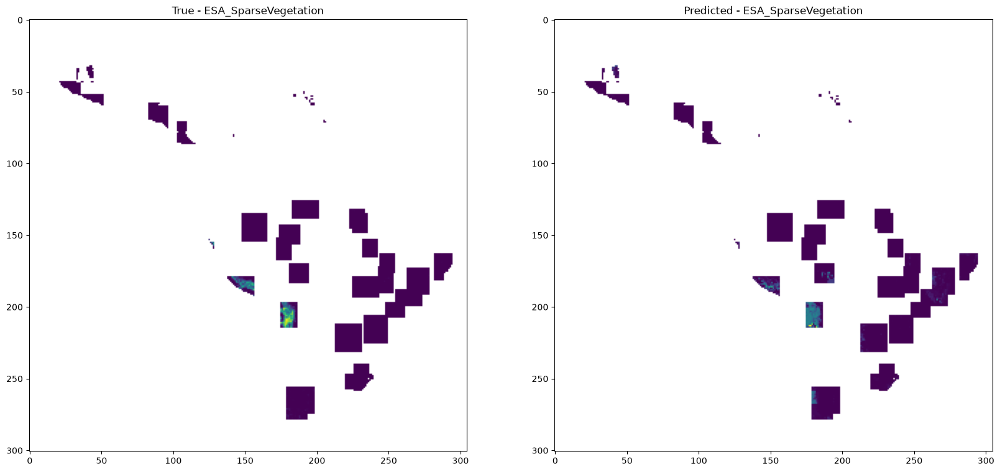

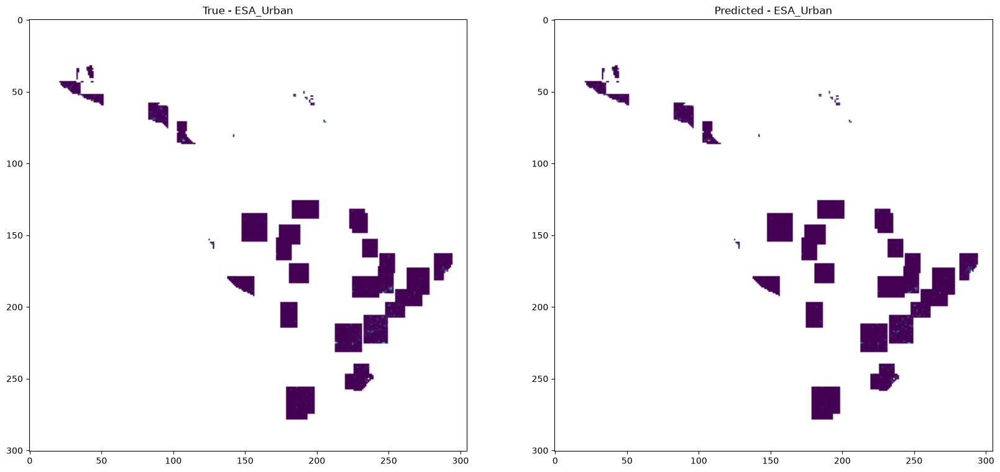

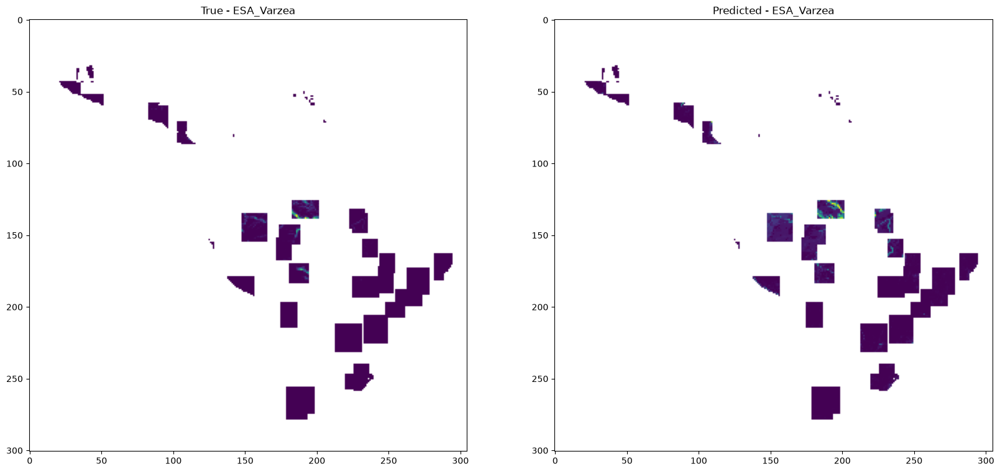

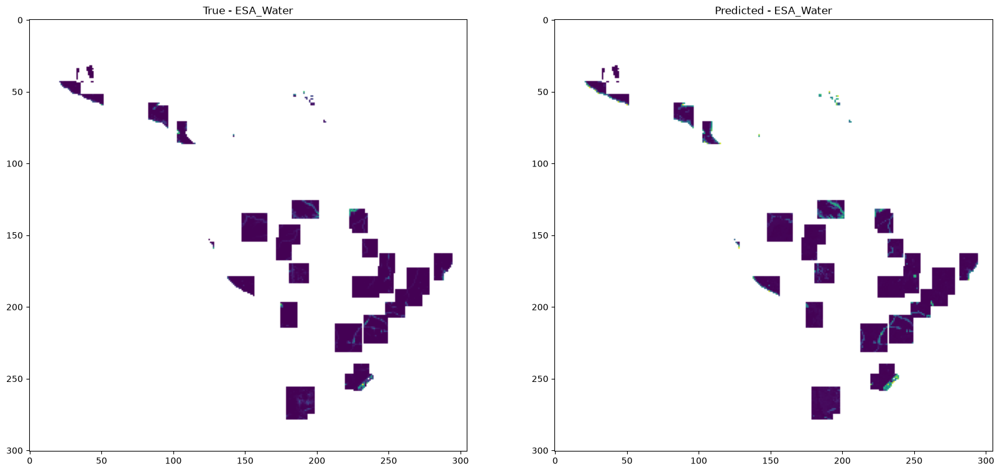

In [66]:
for i, r in enumerate(response):
    pred_channel = pred_raster[:, :, i]
    pred_channel = pred_raster[:, :, i].reshape(*pred_channel.shape, 1)

    val_channel = val_raster[:, :, i]
    val_channel = val_raster[:, :, i].reshape(*val_channel.shape, 1)

    fig = plt.figure(figsize=(20, 10))    
    plt.subplot(1, 2, 1)
    plt.imshow(val_channel)
    plt.title(f'True - {r}')

    plt.subplot(1, 2, 2)
    plt.imshow(pred_channel)
    plt.title(f'Predicted - {r}')
    plt.show()

<Figure size 640x480 with 0 Axes>

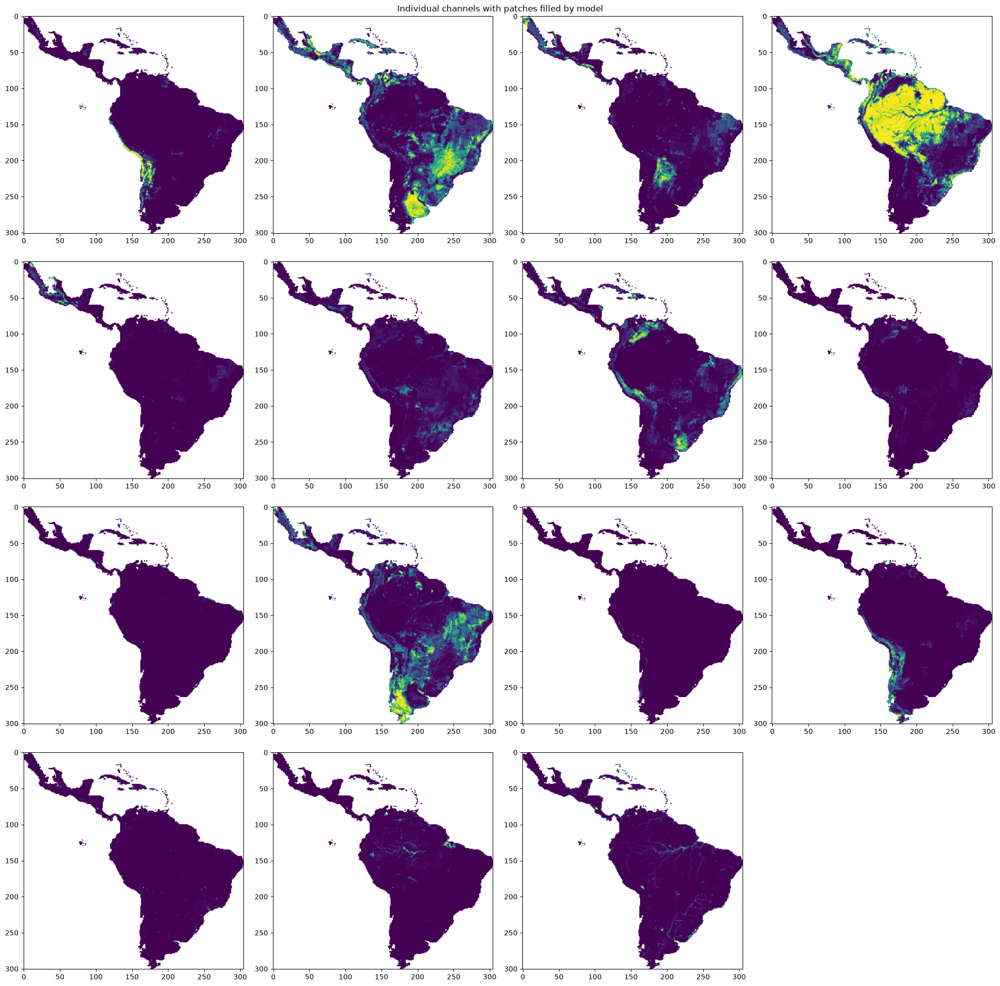

In [79]:
show_raster(to_img(pred_df_with_training, masked=True))
fig = plt.gcf()
fig.suptitle('Individual channels with patches filled by model')
fig.tight_layout()


# Error analysis

In [67]:
print('MSE across all channels:', round(((val_raster - pred_raster) ** 2).mean(), 6))

MSE across all channels: 0.007101


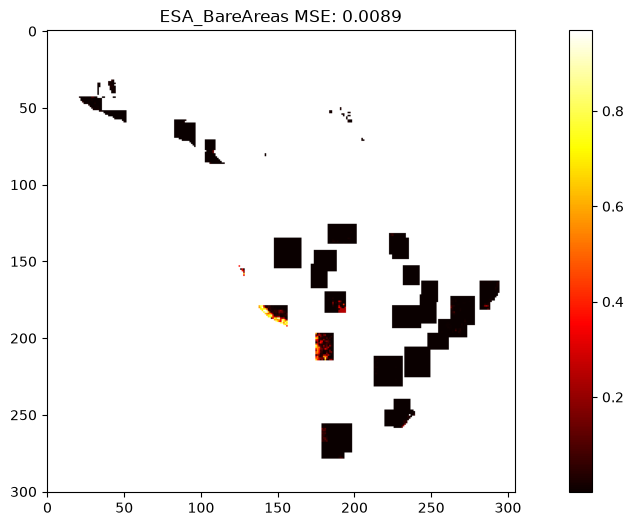

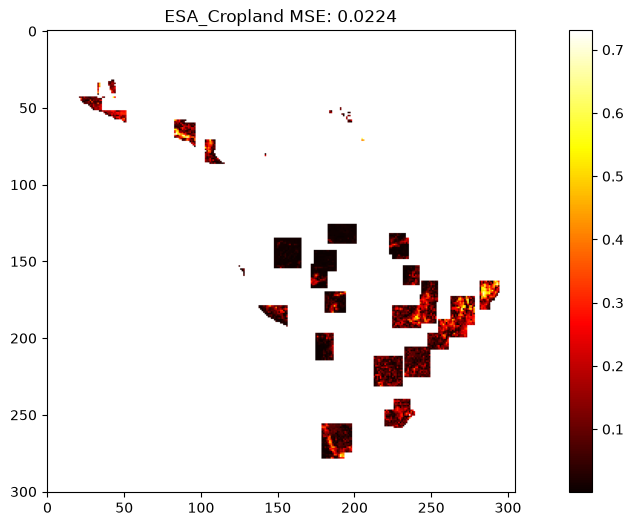

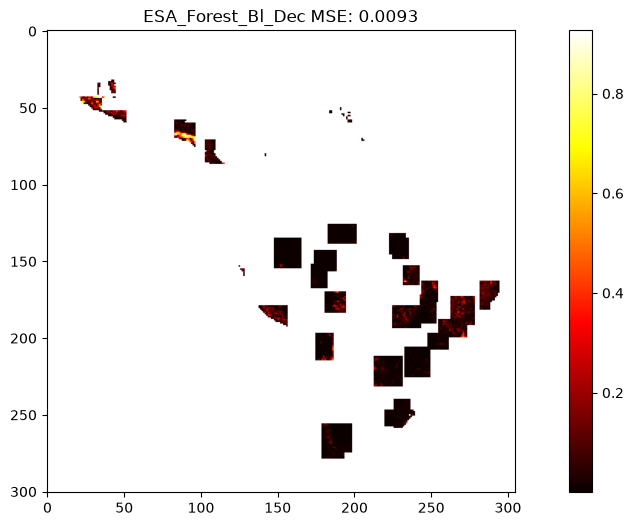

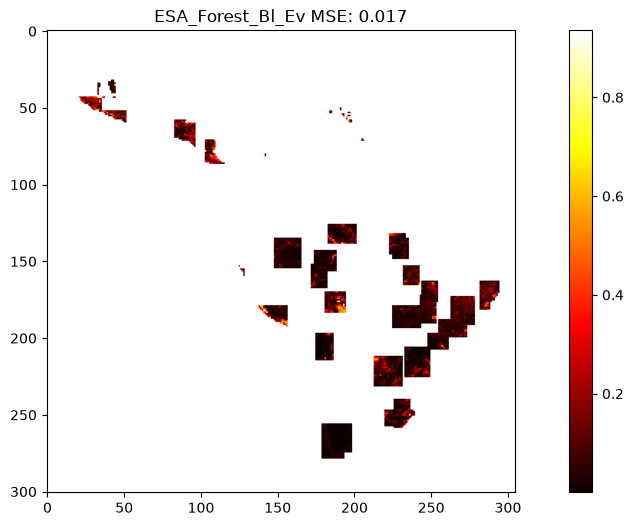

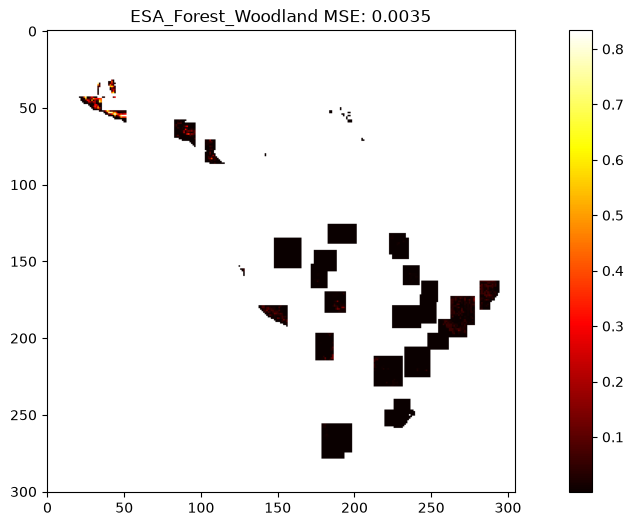

...

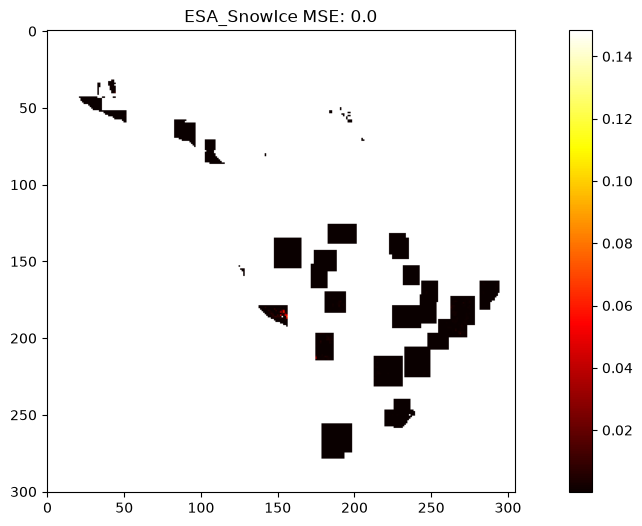

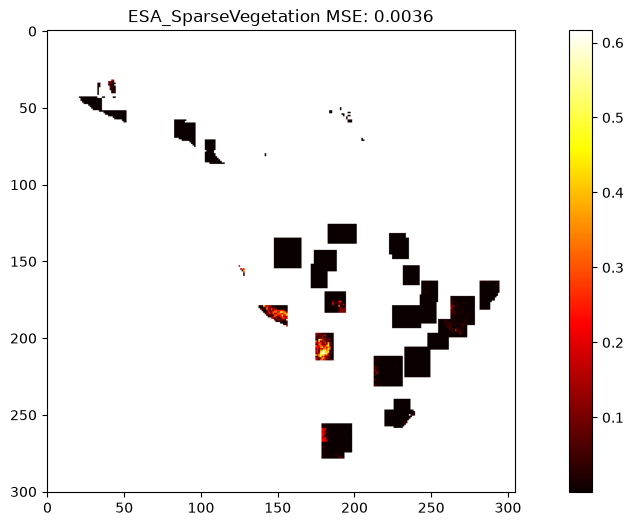

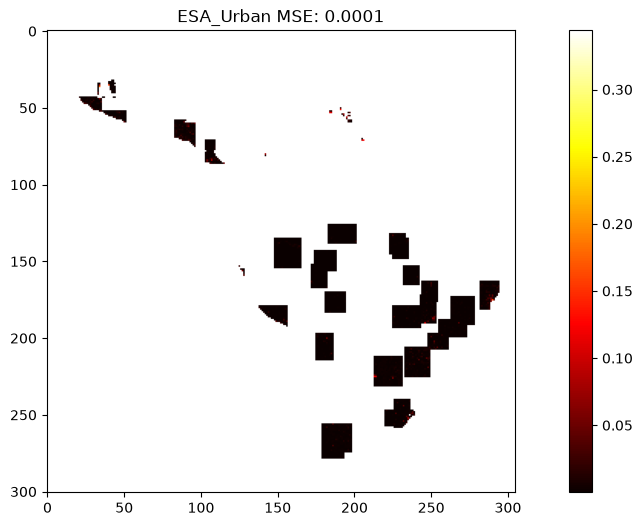

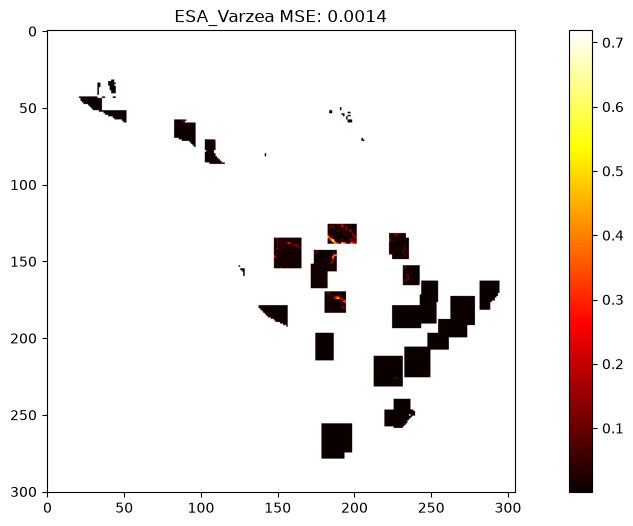

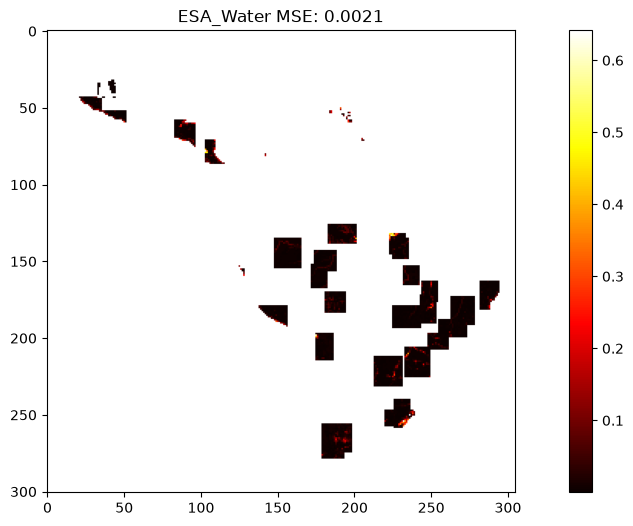

ESA_SnowIce             0.000009
ESA_Urban               0.000100
ESA_GrasslandMosaic     0.000245
ESA_Mangrove            0.000385
ESA_Varzea              0.001402
ESA_Water               0.002052
ESA_ForestMosaic        0.003433
ESA_Forest_Woodland     0.003452
ESA_SparseVegetation    0.003634
ESA_BareAreas           0.008900
ESA_Forest_Bl_Dec       0.009336
ESA_Grassland           0.012152
ESA_Forest_Bl_Ev        0.016954
ESA_Shrubland           0.022058
ESA_Cropland            0.022402
Name: MSE, dtype: float64

In [68]:
metric = pd.Series(name='MSE')
for i, r in enumerate(response):
    show_raster(abs(val_raster - pred_raster)[:, :, i], cmap='hot', fig=plt.figure(figsize=(14, 6)))
    plt.colorbar()
    mse = ((val_raster - pred_raster) ** 2)[:, :, i].mean()
    metric[r] = mse
    plt.title(f"{r} MSE: {mse.round(4)}")
    plt.show()

metric.sort_values()